# AI Programming Foundations Project: Titanic Data Workflow

**Name:** Mohammad AfsharNejad

**Dataset:** Titanic - Machine Learning from Disaster (Kaggle): https://www.kaggle.com/c/titanic/data

**Project description:** This notebook builds a reproducible data workflow for the Kaggle Titanic passenger data (891 passengers, 12 columns). It loads the raw CSV, cleans it with documented functions, explores survival patterns with a reusable analysis function, and saves three labeled figures. The cleaned data and the workflow are meant as a foundation for later machine learning work.

## 1. Introduction

The goal is to understand which passenger characteristics are linked to survival on the Titanic and to prepare a clean, well-documented table for later modeling. The workflow follows five steps: ingestion, cleaning, exploratory analysis, visualization and summary. All paths are relative, so the notebook runs from the project folder with `Kernel > Restart & Run All`.

### Data dictionary (key columns)

| Column | Meaning | Type in raw file |
|---|---|---|
| `PassengerId` | Row identifier | integer |
| `Survived` | Target: 0 = died, 1 = survived | integer |
| `Pclass` | Ticket class: 1 = first, 2 = second, 3 = third | integer |
| `Name` | Passenger name | text |
| `Sex` | `male` or `female` | text |
| `Age` | Age in years (fractional for infants) | float |
| `SibSp` | Number of siblings or spouses aboard | integer |
| `Parch` | Number of parents or children aboard | integer |
| `Ticket` | Ticket number | text |
| `Fare` | Ticket price (British pounds) | float |
| `Cabin` | Cabin number | text |
| `Embarked` | Port: C = Cherbourg, Q = Queenstown, S = Southampton | text |

## 2. Imports & Loading

The dataset is read with a relative path (`titanic.csv` in the project folder). The raw DataFrame `raw_df` is never modified; every cleaning step works on a copy.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("titanic.csv")
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

raw_df = pd.read_csv(DATA_PATH)
raw_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,NaN,S


In [2]:
print("Shape (rows, columns):", raw_df.shape)
print("\nColumn data types:")
print(raw_df.dtypes)

Shape (rows, columns): (891, 12)

Column data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [3]:
def report_missing(df, label):
    """Print the number and share of missing values in each column that has any.

    Parameters
    ----------
    df : pandas.DataFrame
        Table to check.
    label : str
        Short description printed above the result (for example "before cleaning").

    Returns
    -------
    pandas.DataFrame
        One row per column with missing values, with the columns
        `missing_count` and `missing_percent`.
    """
    counts = df.isna().sum()
    summary = pd.DataFrame({
        "missing_count": counts,
        "missing_percent": (counts / len(df) * 100).round(1),
    })
    summary = summary[summary["missing_count"] > 0]
    print(f"Missing values {label}: {int(counts.sum())} cells in total")
    return summary


report_missing(raw_df, "in the raw data")

Missing values in the raw data: 866 cells in total


,missing_count,missing_percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


## 3. Data Cleaning

Three columns have missing values: `Age` (177), `Cabin` (687) and `Embarked` (2). Before choosing a fix, the cell below checks whether the missing values are spread evenly across ticket classes. If they are not, a single overall fill value would be misleading.

In [4]:
missing_by_class = (
    raw_df.assign(AgeMissing=raw_df["Age"].isna(), CabinMissing=raw_df["Cabin"].isna())
    .groupby("Pclass")[["AgeMissing", "CabinMissing"]]
    .mean()
    .mul(100)
    .round(1)
)
missing_by_class.columns = ["Age missing (%)", "Cabin missing (%)"]
missing_by_class

,Age missing (%),Cabin missing (%)
Pclass,,
1,13.9,18.5
2,6.0,91.3
3,27.7,97.6


In [5]:
def handle_missing_values(df):
    """Fill or replace the missing values in the Titanic table.

    Steps (on a copy, so the input is not changed):
    1. Age: add an `AgeImputed` flag (1 = age was missing), then fill the
       missing ages with the median age of passengers with the same
       `Pclass` and `Sex`.
    2. Embarked: fill the missing ports with the most frequent port (mode).
    3. Cabin: replace the mostly empty `Cabin` column with a `HasCabin`
       flag (1 = a cabin number was recorded, 0 = no cabin number).

    Parameters
    ----------
    df : pandas.DataFrame
        Raw Titanic data with the columns `Age`, `Pclass`, `Sex`,
        `Embarked` and `Cabin`.

    Returns
    -------
    pandas.DataFrame
        A new DataFrame with no missing values in `Age` or `Embarked`,
        a new `HasCabin` column instead of `Cabin`, and a new
        `AgeImputed` column.
    """
    cleaned = df.copy()

    cleaned["AgeImputed"] = cleaned["Age"].isna().astype(int)
    group_median_age = cleaned.groupby(["Pclass", "Sex"])["Age"].transform("median")
    cleaned["Age"] = cleaned["Age"].fillna(group_median_age)

    most_common_port = cleaned["Embarked"].mode()[0]
    cleaned["Embarked"] = cleaned["Embarked"].fillna(most_common_port)

    cleaned["HasCabin"] = cleaned["Cabin"].notna().astype(int)
    cleaned = cleaned.drop(columns="Cabin")

    print(f"Embarked filled with mode: {most_common_port!r}")
    return cleaned

In [6]:
def standardize_and_engineer(df):
    """Fix data types, remove duplicate rows and add a family-size feature.

    Steps (on a copy, so the input is not changed):
    1. Drop exact duplicate rows and print how many were removed.
    2. Convert `Sex`, `Embarked` and `Pclass` to the pandas `category`
       type, because they hold a small, fixed set of labels.
    3. Add `FamilySize` = `SibSp` + `Parch` + 1 (the passenger).

    Parameters
    ----------
    df : pandas.DataFrame
        Titanic data after `handle_missing_values`.

    Returns
    -------
    pandas.DataFrame
        A new DataFrame with categorical types and a `FamilySize` column.
    """
    standardized = df.copy()

    rows_before = len(standardized)
    standardized = standardized.drop_duplicates().reset_index(drop=True)
    print(f"Duplicate rows removed: {rows_before - len(standardized)}")

    for column in ["Sex", "Embarked", "Pclass"]:
        standardized[column] = standardized[column].astype("category")

    standardized["FamilySize"] = standardized["SibSp"] + standardized["Parch"] + 1
    return standardized

### Apply the cleaning functions

The median ages used for imputation are shown first, so the fill values are visible. Then both functions run in order, and the missing-value report is repeated.

In [7]:
median_age_table = raw_df.groupby(["Pclass", "Sex"])["Age"].median().unstack()
print("Median age used for imputation (rows = Pclass, columns = Sex):")
print(median_age_table)
print()

display(report_missing(raw_df, "before cleaning"))

clean_df = handle_missing_values(raw_df)
clean_df = standardize_and_engineer(clean_df)

display(report_missing(clean_df, "after cleaning"))
print("Shape after cleaning:", clean_df.shape)
print("Rows with an imputed age:", int(clean_df["AgeImputed"].sum()))
print("\nData types after cleaning:")
print(clean_df.dtypes)

Median age used for imputation (rows = Pclass, columns = Sex):
Sex     female  male
Pclass              
1         35.0  40.0
2         28.0  30.0
3         21.5  25.0

Missing values before cleaning: 866 cells in total


,missing_count,missing_percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Embarked filled with mode: 'S'
Duplicate rows removed: 0
Missing values after cleaning: 0 cells in total


,missing_count,missing_percent


Shape after cleaning: (891, 14)
Rows with an imputed age: 177

Data types after cleaning:
PassengerId       int64
Survived          int64
Pclass         category
Name                str
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Embarked       category
AgeImputed        int64
HasCabin          int64
FamilySize        int64
dtype: object


In [8]:
print("Age standard deviation, observed values only:", round(raw_df["Age"].std(), 2))
print("Age standard deviation, after imputation:   ", round(clean_df["Age"].std(), 2))
print("Raw data unchanged (still 177 missing ages):", int(raw_df["Age"].isna().sum()) == 177)
clean_df.head()

Age standard deviation, observed values only: 14.53
Age standard deviation, after imputation:    13.3
Raw data unchanged (still 177 missing ages): True


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,AgeImputed,HasCabin,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,S,0,0,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.283,C,0,1,2
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,S,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.100,S,0,1,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,S,0,0,1


## 4. Exploratory Analysis

`explore` collects the main descriptive results in one call: summary statistics, survival rates by group and a correlation matrix. It returns the results in a dictionary, so later cells (and later projects) can reuse them.

In [9]:
def explore(df, group_columns=("Sex", "Pclass", "Embarked")):
    """Run the core exploratory analysis on the cleaned Titanic table.

    Parameters
    ----------
    df : pandas.DataFrame
        Cleaned Titanic data with a numeric `Survived` column.
    group_columns : sequence of str, optional
        Columns used to group the survival rate. Default: Sex, Pclass, Embarked.

    Returns
    -------
    dict
        - "overall_survival_rate": float, share of passengers who survived.
        - "summary_statistics": DataFrame from `describe()` on the numeric columns.
        - "survival_by_<column>": DataFrame with passenger count and survival
          rate (%) for each group, one entry per column in `group_columns`.
        - "correlation": DataFrame with the Pearson correlation of the numeric
          columns, plus `Pclass` as a number and `Sex` as a 0/1 `IsMale` flag.
    """
    results = {
        "overall_survival_rate": df["Survived"].mean(),
        "summary_statistics": df.describe(),
    }

    for column in group_columns:
        grouped = df.groupby(column, observed=True)["Survived"].agg(["count", "mean"])
        grouped = grouped.rename(columns={"count": "passengers", "mean": "survival_rate_%"})
        grouped["survival_rate_%"] = (grouped["survival_rate_%"] * 100).round(1)
        results[f"survival_by_{column}"] = grouped

    numeric = df.select_dtypes(include="number").drop(columns=["PassengerId"], errors="ignore")
    numeric = numeric.assign(
        Pclass=df["Pclass"].astype(int),
        IsMale=(df["Sex"] == "male").astype(int),
    )
    results["correlation"] = numeric.corr().round(2)
    return results

In [10]:
eda = explore(clean_df)

print(f"Overall survival rate: {eda['overall_survival_rate'] * 100:.1f}%")
display(eda["summary_statistics"])
for column in ["Sex", "Pclass", "Embarked"]:
    display(eda[f"survival_by_{column}"])

Overall survival rate: 38.4%


,PassengerId,Survived,Age,SibSp,Parch,Fare,AgeImputed,HasCabin,FamilySize
count,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000
mean,446.000,0.384,29.112,0.523,0.382,32.204,0.199,0.229,1.905
std,257.354,0.487,13.304,1.103,0.806,49.693,0.399,0.420,1.613
min,1.000,0.000,0.420,0.000,0.000,0.000,0.000,0.000,1.000
25%,223.500,0.000,21.500,0.000,0.000,7.910,0.000,0.000,1.000
50%,446.000,0.000,26.000,0.000,0.000,14.454,0.000,0.000,1.000
75%,668.500,1.000,36.000,1.000,0.000,31.000,0.000,0.000,2.000
max,891.000,1.000,80.000,8.000,6.000,512.329,1.000,1.000,11.000


,passengers,survival_rate_%
Sex,,
female,314,74.2
male,577,18.9


,passengers,survival_rate_%
Pclass,,
1,216,63.0
2,184,47.3
3,491,24.2


,passengers,survival_rate_%
Embarked,,
C,168,55.4
Q,77,39.0
S,646,33.9


In [11]:
eda["correlation"]

,Survived,Age,SibSp,Parch,Fare,AgeImputed,HasCabin,FamilySize,Pclass,IsMale
Survived,1.00,-0.06,-0.04,0.08,0.26,-0.09,0.32,0.02,-0.34,-0.54
Age,-0.06,1.00,-0.25,-0.18,0.12,-0.09,0.28,-0.26,-0.41,0.10
SibSp,-0.04,-0.25,1.00,0.41,0.16,0.02,-0.04,0.89,0.08,-0.11
Parch,0.08,-0.18,0.41,1.00,0.22,-0.12,0.04,0.78,0.02,-0.25
Fare,0.26,0.12,0.16,0.22,1.00,-0.10,0.48,0.22,-0.55,-0.18
AgeImputed,-0.09,-0.09,0.02,-0.12,-0.10,1.00,-0.14,-0.05,0.17,0.06
HasCabin,0.32,0.28,-0.04,0.04,0.48,-0.14,1.00,-0.01,-0.73,-0.14
FamilySize,0.02,-0.26,0.89,0.78,0.22,-0.05,-0.01,1.00,0.07,-0.20
Pclass,-0.34,-0.41,0.08,0.02,-0.55,0.17,-0.73,0.07,1.00,0.13
IsMale,-0.54,0.10,-0.11,-0.25,-0.18,0.06,-0.14,-0.20,0.13,1.00


Two extra checks use the same `explore` function on subgroups: survival by class within each sex, and survival for passengers with and without a recorded age or cabin. These show whether the missing values are linked to the outcome.

In [12]:
survival_by_sex_and_class = (
    clean_df.groupby(["Sex", "Pclass"], observed=True)["Survived"]
    .mean()
    .mul(100)
    .round(1)
    .unstack()
)
print("Survival rate (%) by sex (rows) and class (columns):")
display(survival_by_sex_and_class)

flags = explore(clean_df, group_columns=("AgeImputed", "HasCabin", "FamilySize"))
display(flags["survival_by_AgeImputed"])
display(flags["survival_by_HasCabin"])
display(flags["survival_by_FamilySize"])

Survival rate (%) by sex (rows) and class (columns):


Pclass,1,2,3
Sex,,,
female,96.8,92.1,50.0
male,36.9,15.7,13.5


,passengers,survival_rate_%
AgeImputed,,
0,714,40.6
1,177,29.4


,passengers,survival_rate_%
HasCabin,,
0,687,30.0
1,204,66.7


,passengers,survival_rate_%
FamilySize,,
1,537,30.4
2,161,55.3
3,102,57.8
4,29,72.4
5,15,20.0
6,22,13.6
7,12,33.3
8,6,0.0
11,7,0.0


In [13]:
recorded_ages = clean_df[clean_df["AgeImputed"] == 0].assign(
    AgeBand=lambda d: pd.cut(d["Age"], bins=[0, 10, 18, 30, 50, np.inf], right=False,
                   labels=["0-9", "10-17", "18-29", "30-49", "50+"])
)
age_band_survival = explore(recorded_ages, group_columns=("AgeBand",))["survival_by_AgeBand"]
print("Survival by age band (recorded ages only, n = 714):")
age_band_survival

Survival by age band (recorded ages only, n = 714):


,passengers,survival_rate_%
AgeBand,,
0-9,62,61.3
10-17,51,45.1
18-29,271,35.1
30-49,256,41.8
50+,74,36.5


In [14]:
fare_by_class = clean_df.groupby("Pclass", observed=True)["Fare"].describe()[["count", "mean", "50%", "max"]]
fare_by_class

,count,mean,50%,max
Pclass,,,,
1,216.0,84.155,60.287,512.329
2,184.0,20.662,14.250,73.500
3,491.0,13.676,8.050,69.550


## 5. Visualizations

Each figure has a title and labeled axes and is saved to `figures/` as a PNG file (150 dpi) by the helper `save_figure`.

In [15]:
def save_figure(fig, filename):
    """Save a Matplotlib figure as a 150-dpi PNG file in the figures folder.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure to save.
    filename : str
        File name, for example "figure1_survival_by_sex_class.png".

    Returns
    -------
    pathlib.Path
        Relative path of the saved file.
    """
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.as_posix()}")
    return path

Saved figures/figure1_survival_by_sex_class.png

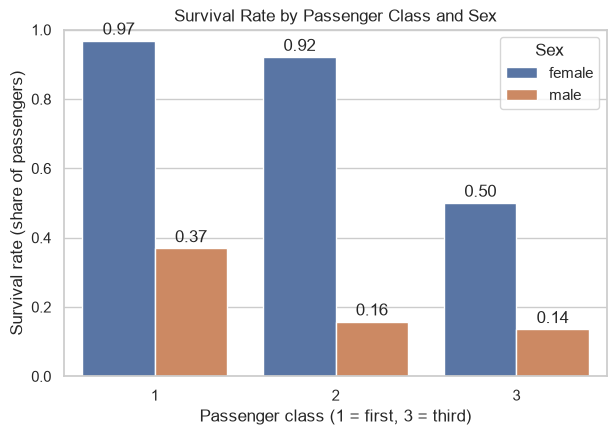

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=clean_df, x="Pclass", y="Survived", hue="Sex", errorbar=None, ax=ax)
ax.set_title("Survival Rate by Passenger Class and Sex")
ax.set_xlabel("Passenger class (1 = first, 3 = third)")
ax.set_ylabel("Survival rate (share of passengers)")
ax.set_ylim(0, 1)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)
ax.legend(title="Sex")
save_figure(fig, "figure1_survival_by_sex_class.png")
plt.show()

Figure 1: Survival rate by passenger class and sex (cleaned data, n = 891). Bar labels show the share of passengers in each group who survived.

Saved figures/figure2_age_distribution_by_survival.png


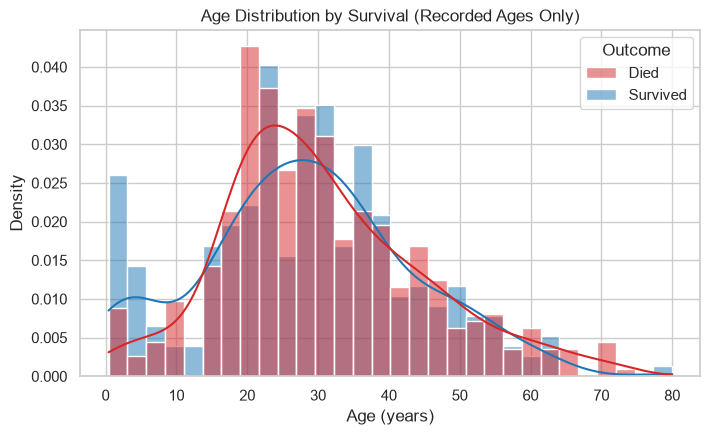

Passengers with a recorded age: 714


In [17]:
observed_age_df = clean_df[clean_df["AgeImputed"] == 0].assign(
    Outcome=lambda d: d["Survived"].map({0: "Died", 1: "Survived"})
)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(
    data=observed_age_df, x="Age", hue="Outcome", hue_order=["Died", "Survived"],
    bins=30, stat="density", common_norm=False, kde=True,
    palette={"Died": "tab:red", "Survived": "tab:blue"}, ax=ax,
)
ax.set_title("Age Distribution by Survival (Recorded Ages Only)")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Density")
save_figure(fig, "figure2_age_distribution_by_survival.png")
plt.show()
print("Passengers with a recorded age:", len(observed_age_df))

Figure 2: Age distribution of survivors and non-survivors, using only the 714 passengers with a recorded age. Imputed ages are left out so the median fill values do not create artificial peaks.

Saved figures/figure3_correlation_heatmap.png


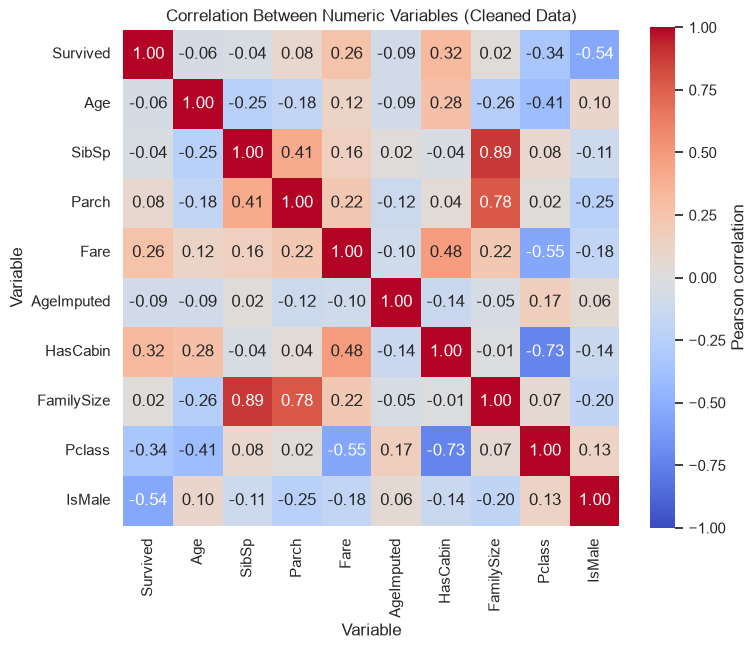

In [18]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    eda["correlation"], annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Correlation Between Numeric Variables (Cleaned Data)")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
save_figure(fig, "figure3_correlation_heatmap.png")
plt.show()

Figure 3: Pearson correlation matrix of the numeric variables after cleaning. `Pclass` is used as a number (1 to 3) and `IsMale` is 1 for male passengers.

## 6. Summary & Interpretation

**What I learned.** I learned that cleaning choices need to be checked against the data before they are applied. The missing-value check showed that `Cabin` is missing for 97.6% of third-class passengers but only 18.5% of first-class passengers, so the missing values are not random. This is why I replaced `Cabin` with a `HasCabin` flag instead of filling it, and why I imputed `Age` within groups of `Pclass` and `Sex` instead of using one overall median. I also learned that keeping the raw DataFrame unchanged and adding flags such as `AgeImputed` makes every cleaning step easy to check later.

**Interesting patterns.** The overall survival rate in the 891 passengers is 38.4%. Sex is the strongest single factor: 74.2% of women survived compared with 18.9% of men, and `IsMale` has the strongest correlation with survival (-0.54) in Figure 3. Class matters as well: survival falls from 63.0% in first class to 47.3% in second class and 24.2% in third class (Figure 1). The two factors combine: 96.8% of first-class women survived, but only 13.5% of third-class men did. Among passengers with a recorded age, children under 10 had the highest survival rate (61.3%), which matches the left peak of the survivor curve in Figure 2. Passengers with a recorded cabin survived at 66.7%, compared with 30.0% for those without one.

**Limitations and assumptions.** I assumed that a passenger's age is similar to the median age of passengers with the same class and sex. This assumption fills all 177 missing ages, but it also lowers the standard deviation of `Age` from 14.53 to 13.30 years and creates repeated values at only six median ages. I assumed that a missing cabin number mainly means that no cabin was recorded, which is closely tied to class (correlation of -0.73 between `HasCabin` and `Pclass`). The two missing `Embarked` values were filled with the most common port, `S`; this affects only 0.2% of rows. The data are a historical sample of 891 of the passengers, so the patterns describe this sample and are not causal claims.

**Surprising or unclear points.** The correlation between `FamilySize` and survival is close to zero (0.02), but the grouped table shows a clear non-linear pattern: passengers travelling alone survived at 30.4%, families of two to four people survived at 55.3% to 72.4%, and larger families mostly survived at much lower rates. A linear correlation therefore hides a real relationship. It is also unclear why passengers who embarked at Cherbourg survived more often (55.4%) than those from Southampton (33.9%); this may reflect differences in class mix rather than the port itself, and it needs a check by class before any conclusion is drawn.
